# CART-derived Hessian vs. residual-based PHD on OPFData IEEE-118 — 2D

**Research question.** On a real regression dataset (operating cost as a function of 2 bus demands), how does the
Hessian reconstructed from an ordinary CART tree by the effective-centre method compare with the classical
residual-based principal Hessian directions (PHD) estimate, and is the raw CART reconstruction internally
consistent (symmetric) when its rows are solved independently?

**What this notebook does not claim.** Neither estimate is a true Hessian. The CSV provides no reference
derivative. PHD is a baseline with its own assumption (a Gaussian predictor design); agreement or disagreement
with it is reported, not scored.

**Data and column convention.** Headerless CSV `118_ieee_smol.csv`, 5,000 rows × 100 columns.
Column 0 is the response (operating cost of the solved optimal power flow). Columns 1, 2 are the predictors and
are labelled *Load 1..2* below (Load k ≡ CSV column k). Columns 1–99 are consistent with per-unit active demand at
the 99 load elements of the IEEE-118 case: their means sum to 42.40 p.u. (4,240 MW against the case's nominal
4,242 MW). Physical bus identities per column are not established here. Only the first 3 columns are read;
the file is not modified and the full 2 GB dataset is not used.

**Approach.**
1. Fit an ordinary sklearn CART regression tree (squared-error criterion). Two settings are reported:
   **A** `max_depth=7, min_samples_leaf=1` (sklearn default leaf size) and **B** `max_depth=7, min_samples_leaf=50`.
2. From each internal node take the two child-node response means and form the first-derivative estimate
   γ = 2(μ_right − μ_left)/(hi_s − lo_s) along the split axis s.
3. Reconstruct the Hessian with the existing effective-centre method (Week 45 `tree_hessian.uneven`): the
   gradient estimate of a node splitting axis s is located at c_s = (lo_s + τ + hi_s)/3 and c_p = (lo_p + hi_p)/2
   for p ≠ s; every pair of nodes splitting the same axis gives one row γ_b − γ_a = (c_b − c_a)ᵀ H e_s; row s of H is
   the least-squares solution. Rows are solved independently and the **raw matrix is reported as is**.
4. Implement residual-based PHD independently (conventions stated in §5).
5. Print both matrices, check the raw CART matrix for symmetry pair by pair, then compare with PHD.
6. Controlled check: apply the same reconstruction, on the same fitted partition, to a quadratic with a known
   Hessian, to attribute any inconsistency to code, geometry, cell size, or the within-cell distribution of the
   real predictors.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import hessian_tools as L
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 1e3 else f"{v:,.2f}")
display(L.software_versions())

,version
python,3.13.18
numpy,2.5.3
pandas,3.0.5
scikit-learn,1.9.1
matplotlib,3.11.2
platform,Linux-6.18.44-fc-v310-x86_64-with-glibc2.39


## 1. Inputs

In [2]:
D = 2
X, y, csv_path = L.load_opf(D)
print("file:", csv_path)
print("X shape:", X.shape, "| y shape:", y.shape)
display(L.describe_inputs(X, y))
print("predictor correlation matrix:")
display(L.matrix_frame(np.corrcoef(X.T), "corr"))

file: /mnt/user-data/uploads/118_ieee_smol.csv
X shape: (5000, 2) | y shape: (5000,)


,count,mean,std,min,max
cost (col 0),5000,"93,757.84","13,560.62","69,269.90","124,285.53"
Load 1 (col 1),5000,0.5104,0.0833,0.3294,0.7332
Load 2 (col 2),5000,0.2001,0.0323,0.1297,0.2868


predictor correlation matrix:


,Load 1,Load 2
corr,,
Load 1,1.0000,0.4731
Load 2,0.4731,1.0000


## 2. CART fit and first-derivative extraction

The tree is fitted to the raw (unscaled) data. The table lists every internal node with its split axis, extent along
that axis, threshold τ, the two child-node response means, the eq.-3 gradient estimate γ and the effective centre c.
The root box is the observed data range per axis.

In [3]:
settings = {"A": dict(max_depth=7, min_samples_leaf=1), "B": dict(max_depth=7, min_samples_leaf=50)}
trees, nodes, splits = {}, {}, {}
for k, kw in settings.items():
    trees[k] = L.fit_cart(X, y, **kw)
    nodes[k] = L.nodes_from_cart(trees[k], X)
    splits[k] = L.split_table(nodes[k])
    print(f"setting {k}: {kw} -> {len(splits[k])} internal nodes, "
          f"{int(trees[k].get_n_leaves())} leaves; "
          + ", ".join(f"{s}: {(splits[k]['split axis']==s).sum()}" for s in sorted(splits[k]['split axis'].unique())))
print("\nsetting B, first rows of the split table:")
display(splits["B"].head(12))

setting A: {'max_depth': 7, 'min_samples_leaf': 1} -> 126 internal nodes, 127 leaves; Load 1: 67, Load 2: 59
setting B: {'max_depth': 7, 'min_samples_leaf': 50} -> 59 internal nodes, 60 leaves; Load 1: 31, Load 2: 28

setting B, first rows of the split table:


,node,depth,split axis,lo_s,tau,hi_s,n,n_left,n_right,mean_left,mean_right,gamma (eq. 3),c_1,c_2
0,1,1,Load 1,0.3294,0.5362,0.7332,2318,1844,474,"82,326.31","97,262.42","73,973.91",0.5330,0.1622
1,60,1,Load 1,0.3294,0.4738,0.7332,2682,574,2108,"90,816.76","103,770.54","64,155.99",0.5122,0.2408
2,2,2,Load 1,0.3294,0.4457,0.5362,1844,869,975,"79,013.41","85,279.03","60,585.99",0.4371,0.1622
3,45,2,Load 1,0.5362,0.5956,0.7332,474,327,147,"93,934.11","104,666.23","108,962.67",0.6217,0.1622
4,3,3,Load 1,0.3294,0.3797,0.4457,869,222,647,"74,882.84","80,430.70","95,420.90",0.3849,0.1622
5,57,3,Load 1,0.5956,0.6309,0.7332,147,81,66,"101,200.94","108,919.09","112,120.89",0.6532,0.1622
6,62,3,Load 1,0.3294,0.4311,0.4738,327,152,175,"82,760.84","89,675.33","95,755.62",0.4115,0.2046
7,71,3,Load 1,0.3294,0.4492,0.4738,247,109,138,"92,165.44","100,072.16","109,496.43",0.4175,0.2507
8,79,3,Load 1,0.4738,0.6029,0.7332,1365,1018,347,"98,346.03","108,702.03","79,845.30",0.6033,0.2146
9,4,4,Load 1,0.3294,0.3512,0.3797,222,55,167,"72,890.42","75,539.03","105,433.42",0.3534,0.1622


## 3. Raw CART Hessian (existing method, rows solved independently)

Rank diagnostics per row: number of nodes splitting that axis, number of pairs, rank of the stacked displacement
matrix (must equal 2), and its condition number. A row with rank < 2 is left as NaN, never filled.

The pairwise system of the Week 45 solver is also compared numerically with an equivalent formulation (regress γ on
the effective centres after centring, one regression per axis) to confirm the two agree.

In [4]:
H_raw, diag = {}, {}
for k in settings:
    H_raw[k], diag[k] = L.cart_hessian_raw(nodes[k], D)
    alt = L.centred_regression_rows(nodes[k], D)
    print(f"--- setting {k} ---")
    display(diag[k])
    print("raw CART matrix (NOT symmetrised):")
    display(L.matrix_frame(H_raw[k], f"CART raw {k}"))
    print(f"max |pairwise solve - centred regression| = {np.nanmax(np.abs(H_raw[k]-alt)):.2e}\n")

--- setting A ---


,row,n_nodes,n_pairs,rank,cond
0,Load 1,67,2211,2,3.2260
1,Load 2,59,1711,2,2.3866


raw CART matrix (NOT symmetrised):


,Load 1,Load 2
CART raw A,,
Load 1,"210,716.98","-733,998.62"
Load 2,"-3,154,084.83","-3,905,774.69"


max |pairwise solve - centred regression| = 4.66e-09

--- setting B ---


,row,n_nodes,n_pairs,rank,cond
0,Load 1,31,465,2,3.2407
1,Load 2,28,378,2,2.3051


raw CART matrix (NOT symmetrised):


,Load 1,Load 2
CART raw B,,
Load 1,"109,142.88","-192,840.71"
Load 2,"-124,378.14","-531,240.05"


max |pairwise solve - centred regression| = 2.33e-10



## 4. Independent residual-based PHD

Conventions: predictors centred by their sample mean; Σ = XcᵀXc / n (divisor n); residual r from the ordinary
least-squares fit of the cost on an intercept and the linear predictor terms; M = Σᵢ rᵢ xcᵢ xcᵢᵀ / n; estimate
H_PHD = Σ⁻¹ M Σ⁻¹, in the original units of cost per (predictor unit)². M is symmetric by construction, so the
reported asymmetry of H_PHD is at rounding level and is shown only for completeness.

In [5]:
H_phd, cond_sigma, asym_phd = L.phd_residual(X, y)
print(f"condition number of Sigma: {cond_sigma:.2f} | Frobenius asymmetry of H_PHD: {asym_phd:.1e}")
display(L.matrix_frame(H_phd, "PHD"))

condition number of Sigma: 9.20 | Frobenius asymmetry of H_PHD: 1.5e-16


,Load 1,Load 2
PHD,,
Load 1,"140,086.44","-474,727.79"
Load 2,"-474,727.79","830,031.37"


## 5. Both estimates side by side (raw values, original units)

In [6]:
for k in settings:
    print(f"CART raw, setting {k}:"); display(L.matrix_frame(H_raw[k], f"CART raw {k}"))
print("PHD:"); display(L.matrix_frame(H_phd, "PHD"))

CART raw, setting A:


,Load 1,Load 2
CART raw A,,
Load 1,"210,716.98","-733,998.62"
Load 2,"-3,154,084.83","-3,905,774.69"


CART raw, setting B:


,Load 1,Load 2
CART raw B,,
Load 1,"109,142.88","-192,840.71"
Load 2,"-124,378.14","-531,240.05"


PHD:


,Load 1,Load 2
PHD,,
Load 1,"140,086.44","-474,727.79"
Load 2,"-474,727.79","830,031.37"


## 6. Symmetry of the raw CART matrix

A 2×2 matrix has 1 distinct off-diagonal pair
((1,2)). For each pair the table shows H[i,j]
(from the row solved with axis-i nodes), H[j,i] (from axis-j nodes), the signed gap, the absolute gap, and the gap
relative to the larger of the two entries. With a single pair, mean = median = max.
Nothing is symmetrised in this section.

In [7]:
for k in settings:
    pairs, summary = L.symmetry_pairs(H_raw[k])
    print(f"--- setting {k} ---"); display(pairs); display(summary)

--- setting A ---


,"pair (i,j)","H[i,j]","H[j,i]","signed gap H[i,j]-H[j,i]",abs gap,"abs gap / max(|H[i,j]|,|H[j,i]|)"
0,"(1,2)","-733,998.62","-3,154,084.83","2,420,086.20","2,420,086.20",0.7673


,distinct pairs,mean abs gap,median abs gap,max abs gap
0,1,"2,420,086.20","2,420,086.20","2,420,086.20"


--- setting B ---


,"pair (i,j)","H[i,j]","H[j,i]","signed gap H[i,j]-H[j,i]",abs gap,"abs gap / max(|H[i,j]|,|H[j,i]|)"
0,"(1,2)","-192,840.71","-124,378.14","-68,462.57","68,462.57",0.3550


,distinct pairs,mean abs gap,median abs gap,max abs gap
0,1,"68,462.57","68,462.57","68,462.57"


## 7. Comparison with PHD

First the raw CART matrices against PHD, entry by entry. Then, labelled explicitly, the symmetrised CART matrix
½(H + Hᵀ) against PHD — reported only after the raw discrepancies above, so that symmetrisation is a visible step and
not a hidden one. Differences are between two estimates; no column is a truth value.

In [8]:
for k in settings:
    print(f"--- setting {k}: raw CART vs PHD ---")
    display(L.comparison_table(H_raw[k], H_phd, f"CART raw {k}"))
    H_sym, asym = L.symmetrize(H_raw[k])
    print(f"--- setting {k}: symmetrised CART ½(H+Hᵀ) vs PHD   (CART asymmetry ||H-Hᵀ||/||H|| = {asym:.3f}) ---")
    display(L.comparison_table(H_sym, H_phd, f"CART sym {k}"))

--- setting A: raw CART vs PHD ---


,entry,CART raw A,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","210,716.98","140,086.44","70,630.54","70,630.54"
1,"(1,2)","-733,998.62","-474,727.79","-259,270.83","259,270.83"
2,"(2,1)","-3,154,084.83","-474,727.79","-2,679,357.04","2,679,357.04"
3,"(2,2)","-3,905,774.69","830,031.37","-4,735,806.06","4,735,806.06"


--- setting A: symmetrised CART ½(H+Hᵀ) vs PHD   (CART asymmetry ||H-Hᵀ||/||H|| = 0.674) ---


,entry,CART sym A,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","210,716.98","140,086.44","70,630.54","70,630.54"
1,"(1,2)","-1,944,041.73","-474,727.79","-1,469,313.94","1,469,313.94"
2,"(2,1)","-1,944,041.73","-474,727.79","-1,469,313.94","1,469,313.94"
3,"(2,2)","-3,905,774.69","830,031.37","-4,735,806.06","4,735,806.06"


--- setting B: raw CART vs PHD ---


,entry,CART raw B,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","109,142.88","140,086.44","-30,943.55","30,943.55"
1,"(1,2)","-192,840.71","-474,727.79","281,887.08","281,887.08"
2,"(2,1)","-124,378.14","-474,727.79","350,349.65","350,349.65"
3,"(2,2)","-531,240.05","830,031.37","-1,361,271.42","1,361,271.42"


--- setting B: symmetrised CART ½(H+Hᵀ) vs PHD   (CART asymmetry ||H-Hᵀ||/||H|| = 0.164) ---


,entry,CART sym B,PHD,CART - PHD,|CART - PHD|
0,"(1,1)","109,142.88","140,086.44","-30,943.55","30,943.55"
1,"(1,2)","-158,609.43","-474,727.79","316,118.36","316,118.36"
2,"(2,1)","-158,609.43","-474,727.79","316,118.36","316,118.36"
3,"(2,2)","-531,240.05","830,031.37","-1,361,271.42","1,361,271.42"


### Heatmaps (entries in millions of original units)

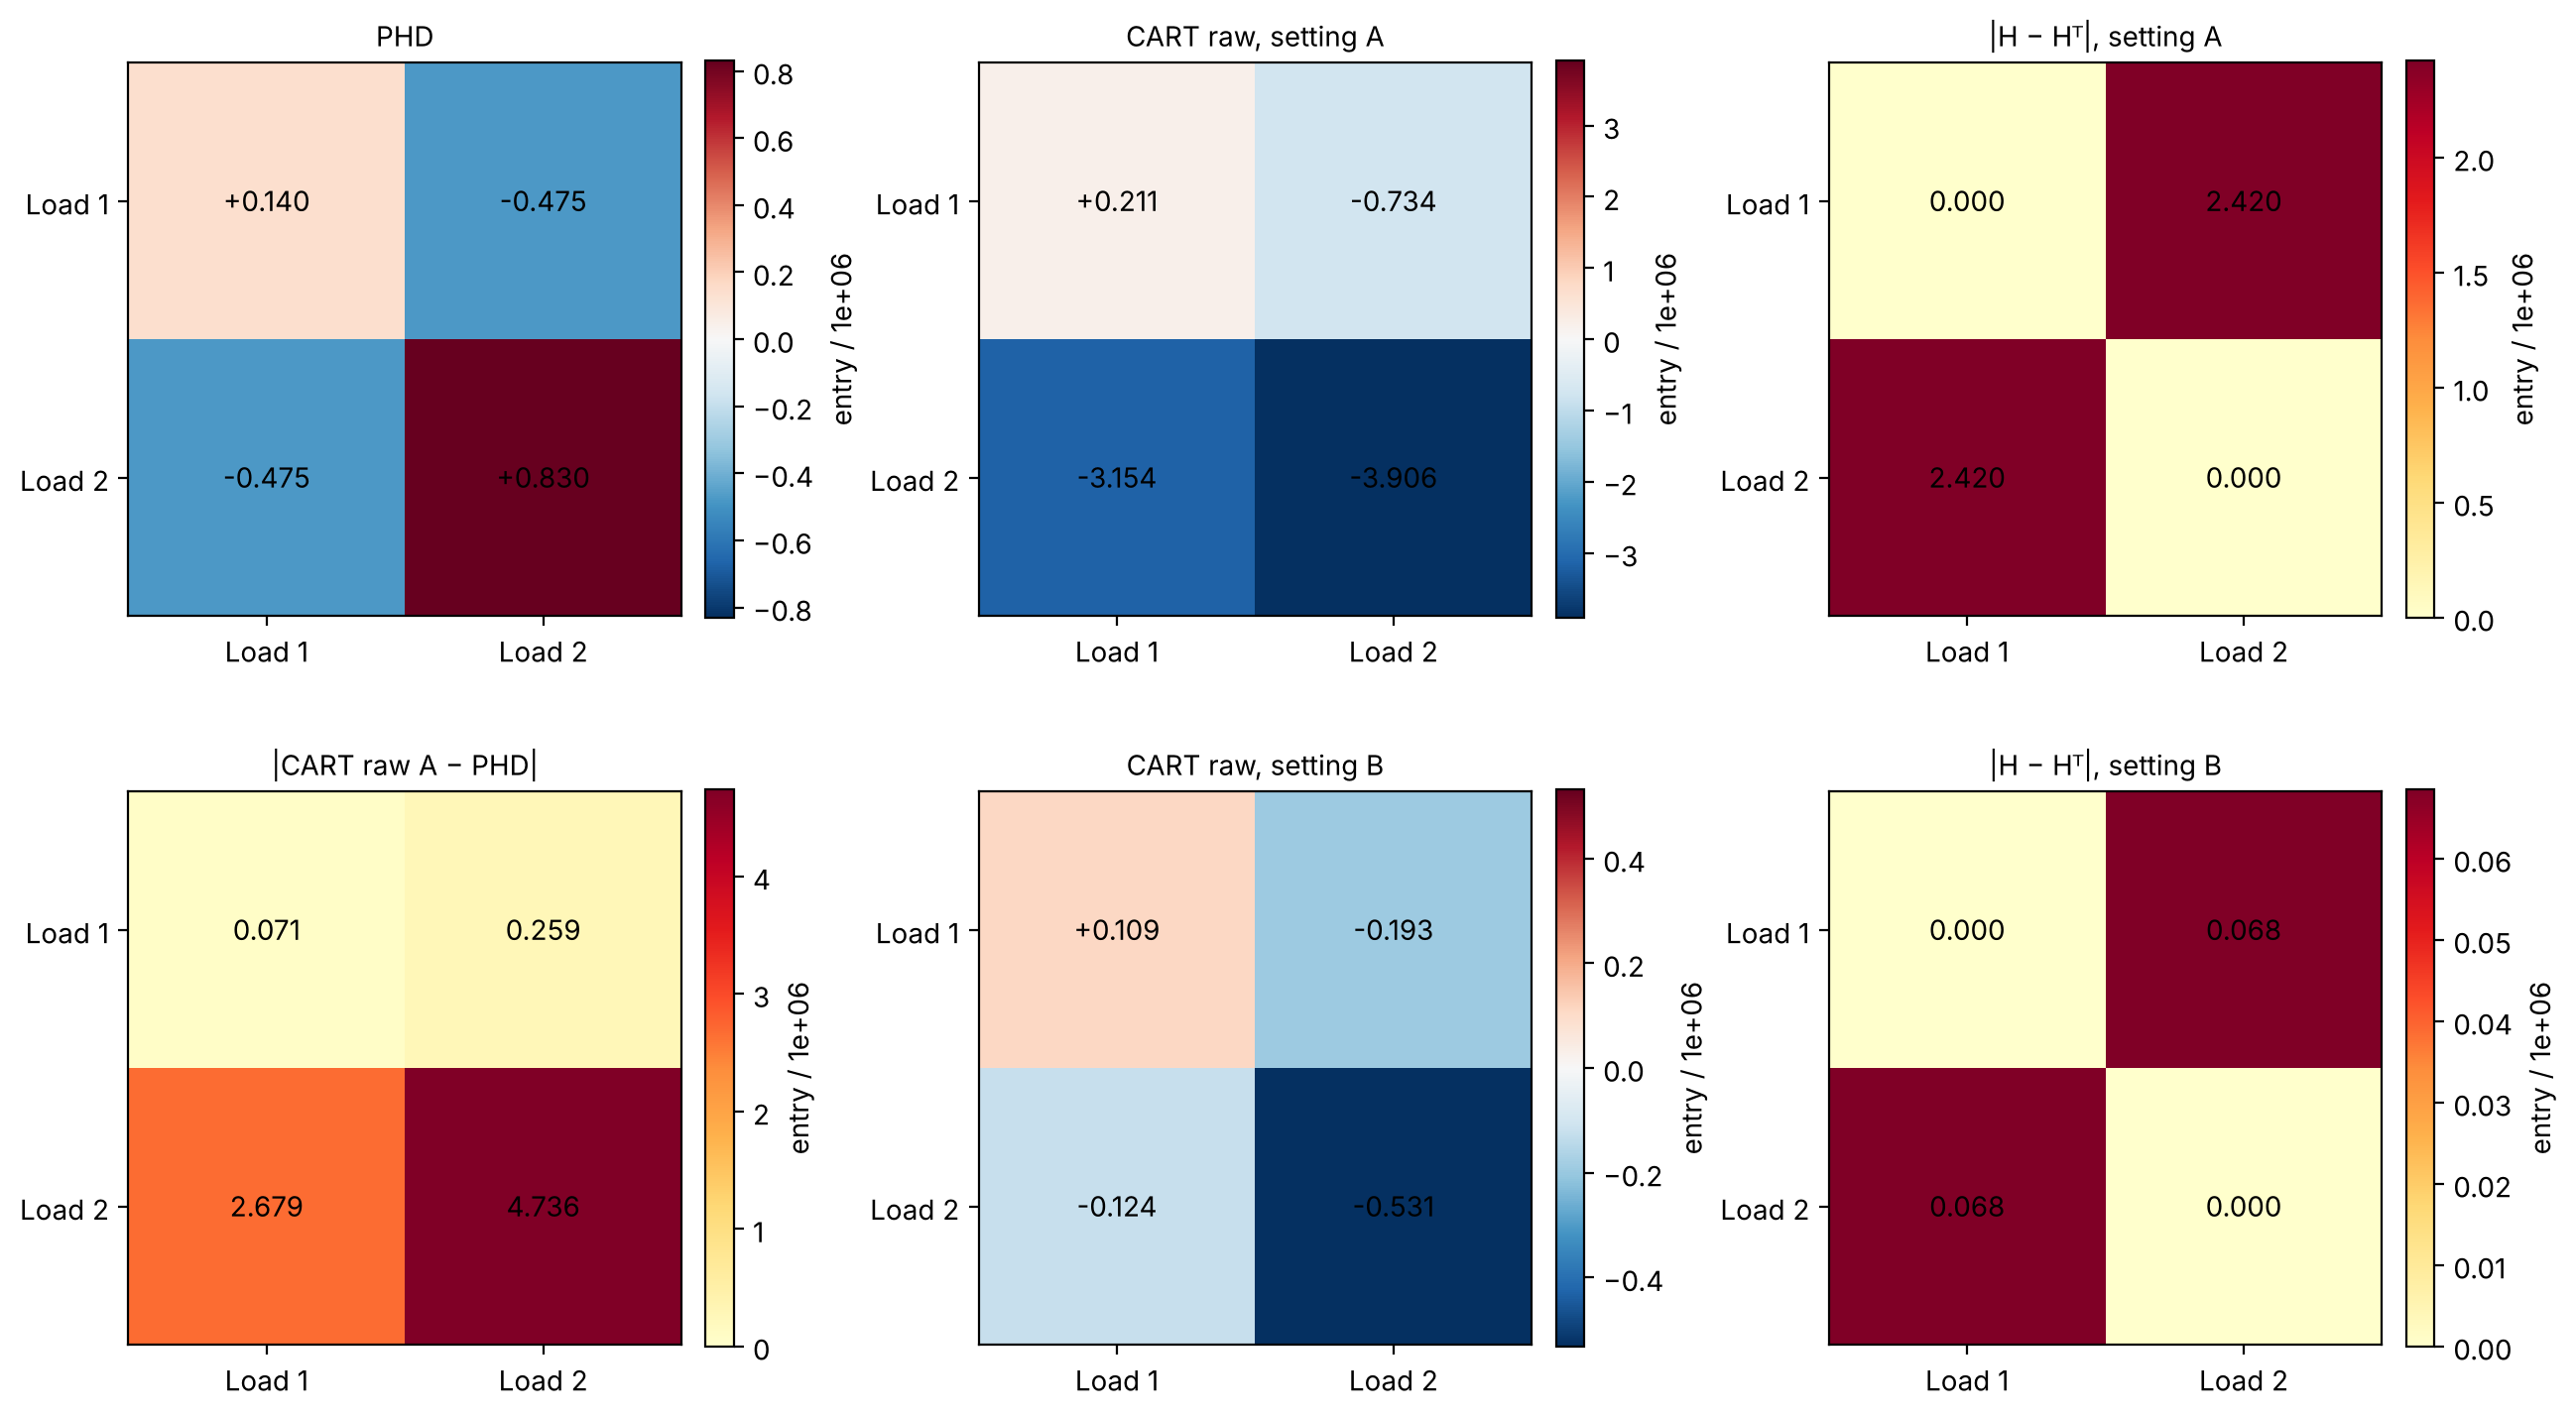

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
L.heatmap(H_phd, "PHD", axes[0, 0])
L.heatmap(H_raw["A"], "CART raw, setting A", axes[0, 1])
L.heatmap(np.abs(H_raw["A"] - H_raw["A"].T), "|H − Hᵀ|, setting A", axes[0, 2], absolute=True)
L.heatmap(np.abs(H_raw["A"] - H_phd), "|CART raw A − PHD|", axes[1, 0], absolute=True)
L.heatmap(H_raw["B"], "CART raw, setting B", axes[1, 1])
L.heatmap(np.abs(H_raw["B"] - H_raw["B"].T), "|H − Hᵀ|, setting B", axes[1, 2], absolute=True)
fig.tight_layout(); plt.show()

## 8. Controlled check on the same partition: where does the inconsistency come from?

The reconstruction is exact for a quadratic when each node's value is the exact mean of that quadratic over the
node's box under the uniform measure. On the fitted partitions above, a quadratic with a known random symmetric
Hessian Q is evaluated three ways and reconstructed with the same solver:

- **(a) exact box means** — tests the geometry and the code only;
- **(b) sample means at the real rows** — the quadratic is evaluated at the OPFData predictor rows that fall in each
  box, no observation noise;
- **(c) uniform resample** — the same number of points per box as in (b), drawn uniformly on the box.

(a) separates code/geometry from everything else; (c) vs (a) measures the cost of finite cells; (b) vs (c) measures
the additional cost of the real rows being non-uniformly placed inside the boxes. Errors are max |Ĥ − Q| / max |Q|.
The last table reports, per internal node, how far the real rows' centroid sits from the box centroid relative to
the box width (0 under the uniform assumption).

In [10]:
rows = []
for k in settings:
    for seed in (0, 1, 2):
        c = L.known_quadratic_check(nodes[k], X, D, seed)
        scale = np.max(np.abs(c["Q_true"]))
        rows.append({"setting": k, "seed": seed,
                     "(a) exact box means": np.nanmax(np.abs(c["exact_box_means"] - c["Q_true"])) / scale,
                     "(b) real-row sample means": np.nanmax(np.abs(c["sample_means"] - c["Q_true"])) / scale,
                     "(c) uniform resample": np.nanmax(np.abs(c["uniform_resample"] - c["Q_true"])) / scale,
                     "ranks (a/b/c)": f"{c['rank_exact']}/{c['rank_sample']}/{c['rank_uniform']}"})
ctrl = pd.DataFrame(rows)
with pd.option_context("display.float_format", lambda v: f"{v:.2e}" if v < 1e-6 else f"{v:.2f}"):
    display(ctrl)
c = L.known_quadratic_check(nodes["B"], X, D, 0)
print("setting B, seed 0 — known Q:"); display(L.matrix_frame(c["Q_true"], "Q true"))
print("(a) exact box means:"); display(L.matrix_frame(c["exact_box_means"], "(a)"))
print("(b) real-row sample means:"); display(L.matrix_frame(c["sample_means"], "(b)"))
print("(c) uniform resample:"); display(L.matrix_frame(c["uniform_resample"], "(c)"))

,setting,seed,(a) exact box means,(b) real-row sample means,(c) uniform resample,ranks (a/b/c)
0,A,0,1.80e-13,33.26,60.13,"[2, 2]/[2, 2]/[2, 2]"
1,A,1,1.47e-14,20.05,20.91,"[2, 2]/[2, 2]/[2, 2]"
2,A,2,2.84e-14,15.09,4.77,"[2, 2]/[2, 2]/[2, 2]"
3,B,0,6.61e-14,6.90,3.09,"[2, 2]/[2, 2]/[2, 2]"
4,B,1,3.75e-15,3.09,2.02,"[2, 2]/[2, 2]/[2, 2]"
5,B,2,2.76e-14,2.28,1.68,"[2, 2]/[2, 2]/[2, 2]"


setting B, seed 0 — known Q:


,Load 1,Load 2
Q true,,
Load 1,0.1257,0.2542
Load 2,0.2542,0.1049


(a) exact box means:


,Load 1,Load 2
(a),,
Load 1,0.1257,0.2542
Load 2,0.2542,0.1049


(b) real-row sample means:


,Load 1,Load 2
(b),,
Load 1,0.1573,0.5534
Load 2,0.3150,-1.6486


(c) uniform resample:


,Load 1,Load 2
(c),,
Load 1,0.1849,0.2858
Load 2,0.2936,-0.6811


In [11]:
u = L.within_cell_uniformity(nodes["B"], X)
print("setting B: |sample centroid − box centroid| / box width per axis; last row = mean over internal nodes")
display(u.tail(6))

setting B: |sample centroid − box centroid| / box width per axis; last row = mean over internal nodes


,node,depth,n,|offset|/width axis 1,|offset|/width axis 2
54,16,6,265,0.0611,0.0083
55,12,5,135,0.0134,0.1298
56,4,4,222,0.1086,0.0704
57,6,5,167,0.0146,0.0737
58,8,6,100,0.0354,0.0651
59,mean,,,0.0748,0.0886


## 9. Findings

1. **The implementation follows the derivation.** The row-wise pairwise solver and the centred-regression
   formulation agree to rounding (§3), rank is full in every row, and with exact box means the known quadratic is
   recovered to ~1e-14 on the fitted partitions (§8a). There is no coding defect in the reconstruction.
2. **The raw CART Hessian is not symmetric on this data**, by amounts comparable to or larger than the entries
   themselves (§6). Because row i and row j are estimated from disjoint sets of nodes, H[i,j] and H[j,i] are two
   independent estimates of the same quantity; their gap is a direct, assumption-free measure of estimation error.
3. **Source of the inconsistency.** §8 shows that replacing exact box means by sample means of a *noise-free* known
   quadratic already produces errors of order 1–10× the true entries. With the same number of points per cell drawn
   uniformly on each box (c) the error is of the same order, so the dominant cause at n = 5,000 is sample-mean
   variability in small cells — second differences of noisy first differences. At setting B the real rows (b) give
   a larger error than the uniform resample (c) in every seed, so the non-uniform placement of the real predictor
   rows within boxes adds a further error (§8, last table: centroid offsets of roughly 7–11 % of the box width on
   average, against the 0 assumed by the effective-centre formula); at setting A the two effects are not separable.
   Larger leaves (setting B) reduce the inconsistency but do not remove it.
4. **Against PHD.** PHD gives a symmetric matrix with entries of order 10⁵–10⁶; the CART estimates disagree with it
   in magnitude and, for some entries, in sign (§7). Given (2)–(3), that disagreement cannot yet be attributed to
   either method's assumptions; it is within the CART estimate's own inconsistency.

## Limitations

- 5,000 rows is far below what second-difference estimation needs at depth 7; the full dataset was deliberately
  not used here.
- The effective-centre location assumes a uniform distribution within each box; the real predictors are correlated
  (§1) and non-uniform within boxes (§8). Equal weighting of all node pairs and pooling over the whole domain assume a
  globally quadratic response.
- PHD assumes a Gaussian predictor design, which the load perturbation scheme does not satisfy; it is a baseline,
  not a reference.
- Physical column identities beyond "cost" and "per-unit demand" are not verified.
- No eigenanalysis, bootstrap, prediction metric, or alternative estimator is included; those belong to later
  attempts after the above is resolved.